# 02. Statistical Experiment Analysis & Decision-Making

**Project**: A/B Testing & Product Experimentation Analytics  
**Project focus**: Experiment design, data quality, and conversion analysis  
**Pre-Experimental Protocol & Decision Framework**:
- **Business Question**: Does the redesigned landing page increase user conversion rate compared to the existing page?
- **Primary Metric**: User-level conversion rate ($CR = \frac{\text{converted users}}{\text{total unique visitors}}$).
- **Null Hypothesis ($H_0$)**: $p_{\text{treatment}} - p_{\text{control}} = 0$ (The new page produces no difference in conversion).
- **Alternative Hypothesis ($H_1$)**: $p_{\text{treatment}} - p_{\text{control}} \neq 0$ (Two-sided test for any significant shift).
- **Significance Level ($\alpha$)**: $0.05$ (Two-sided test, corresponding to 95% confidence).
- **Decision Rule**: Reject $H_0$ if $p\text{-value} < 0.05$ AND the lower bound of the 95% confidence interval is strictly greater than 0. Otherwise, fail to reject $H_0$.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

sys.path.append(os.path.abspath(".."))

from src.metrics import calculate_experiment_metrics
from src.hypothesis_testing import (
    two_proportion_z_test,
    chi_square_test,
    fishers_exact_test,
    sample_ratio_mismatch_test,
    confidence_interval_difference,
)
from src.power_analysis import calculate_mde, calculate_statistical_power, generate_power_curve
from src.bayesian_analysis import run_bayesian_ab_test
from src.database import get_connection

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["Segoe UI", "DejaVu Sans", "Arial"]


## 1. Loading Cleaned Experiment Cohort

We load the verified clean cohort directly from SQLite / processed storage.


In [2]:
clean_df = pd.read_csv("../data/processed/clean_experiment_data.csv")
countries_df = pd.read_csv("../data/raw/countries.csv")
metrics = calculate_experiment_metrics(clean_df)

print(f"Control Cohort Size:   {metrics.n_control:,}")
print(f"Treatment Cohort Size: {metrics.n_treatment:,}")
print(f"Total Experiment Size: {metrics.n_control + metrics.n_treatment:,}")


Control Cohort Size:   145,274
Treatment Cohort Size: 145,310
Total Experiment Size: 290,584


## 2. Sample Ratio Mismatch (SRM) Integrity Check

Before evaluating treatment effects, we must verify that the traffic allocation mechanism was not compromised.
Under a planned 50/50 allocation, we perform a Chi-Square goodness-of-fit test.


In [3]:
srm = sample_ratio_mismatch_test(
    metrics.n_control, metrics.n_treatment, expected_ratio=(0.5, 0.5), alpha=0.01
)

print(f"Observed Control:   {srm.observed_control:,} (Expected: {srm.expected_control:,.1f})")
print(f"Observed Treatment: {srm.observed_treatment:,} (Expected: {srm.expected_treatment:,.1f})")
print(f"SRM Chi-Square Statistic: {srm.chi2_stat:.5f}")
print(f"SRM p-value:             {srm.p_value:.4f}")
print(f"Result: {'SRM DETECTED - ABORT' if srm.is_srm_detected else 'SRM Test Passed (Randomization Valid)'}")


Observed Control:   145,274 (Expected: 145,292.0)
Observed Treatment: 145,310 (Expected: 145,292.0)
SRM Chi-Square Statistic: 0.00446
SRM p-value:             0.9468
Result: SRM Test Passed (Randomization Valid)


## 3. Empirical Primary Metric Estimates

We calculate conversion rates, absolute difference, and relative lift.


In [4]:
print(f"Control Conversion Rate:   {metrics.cr_control*100:.4f}% ({metrics.conversions_control:,} / {metrics.n_control:,})")
print(f"Treatment Conversion Rate: {metrics.cr_treatment*100:.4f}% ({metrics.conversions_treatment:,} / {metrics.n_treatment:,})")
print(f"Absolute Difference:       {metrics.absolute_difference_pp:+.4f} percentage points ({metrics.absolute_difference:+.6f})")
print(f"Relative Lift:             {metrics.relative_lift_pct:+.4f}%")
print(f"Unpooled Standard Error:   {metrics.se_unpooled:.6f}")
print(f"Pooled Standard Error:     {metrics.se_pooled:.6f}")


Control Conversion Rate:   12.0386% (17,489 / 145,274)
Treatment Conversion Rate: 11.8808% (17,264 / 145,310)
Absolute Difference:       -0.1578 percentage points (-0.001578)
Relative Lift:             -1.3110%
Unpooled Standard Error:   0.001204
Pooled Standard Error:     0.001204


## 4. Frequentist Hypothesis Testing

We conduct:
1. Two-proportion pooled Z-test (Standard parametric test for binary A/B tests)
2. Pearson Chi-Square test of independence (2x2 contingency table)
3. 95% Confidence Intervals (Wald and Newcombe Score intervals)


In [5]:
z_res = two_proportion_z_test(
    metrics.conversions_control, metrics.n_control,
    metrics.conversions_treatment, metrics.n_treatment,
    alternative="two-sided", pooled=True
)
print(f"Two-Proportion Pooled Z-score: {z_res.z_stat:.4f}")
print(f"Two-Sided p-value:            {z_res.p_value:.4f}")

chi2_res = chi_square_test(
    metrics.conversions_control, metrics.n_control,
    metrics.conversions_treatment, metrics.n_treatment,
    correction=False
)
print(f"Pearson Chi-Square Statistic:  {chi2_res.chi2_stat:.4f}")
print(f"Chi-Square p-value:            {chi2_res.p_value:.4f}")

ci_wald = confidence_interval_difference(
    metrics.conversions_control, metrics.n_control,
    metrics.conversions_treatment, metrics.n_treatment,
    confidence_level=0.95, method="wald"
)
ci_score = confidence_interval_difference(
    metrics.conversions_control, metrics.n_control,
    metrics.conversions_treatment, metrics.n_treatment,
    confidence_level=0.95, method="score"
)

print(f"95% Wald CI for (p_treat - p_ctrl):  [{ci_wald.lower_pp:+.4f}%, {ci_wald.upper_pp:+.4f}%] pp")
print(f"95% Score CI for (p_treat - p_ctrl): [{ci_score.lower_pp:+.4f}%, {ci_score.upper_pp:+.4f}%] pp")


Two-Proportion Pooled Z-score: -1.3109
Two-Sided p-value:            0.1899
Pearson Chi-Square Statistic:  1.7185
Chi-Square p-value:            0.1899
95% Wald CI for (p_treat - p_ctrl):  [-0.3938%, +0.0781%] pp
95% Score CI for (p_treat - p_ctrl): [-0.3938%, +0.0781%] pp


## 5. Statistical Power Analysis & Minimum Detectable Effect (MDE)

To contextualize why the effect was not significant, we calculate the Minimum Detectable Effect (MDE) under $\alpha = 0.05$ and $80\%$ power, and evaluate post-hoc power for the observed lift.


Prospective MDE (at 80% power): 2.81% relative (0.3383 percentage points)
Post-hoc Power to detect observed effect (-0.16 pp): 25.75%


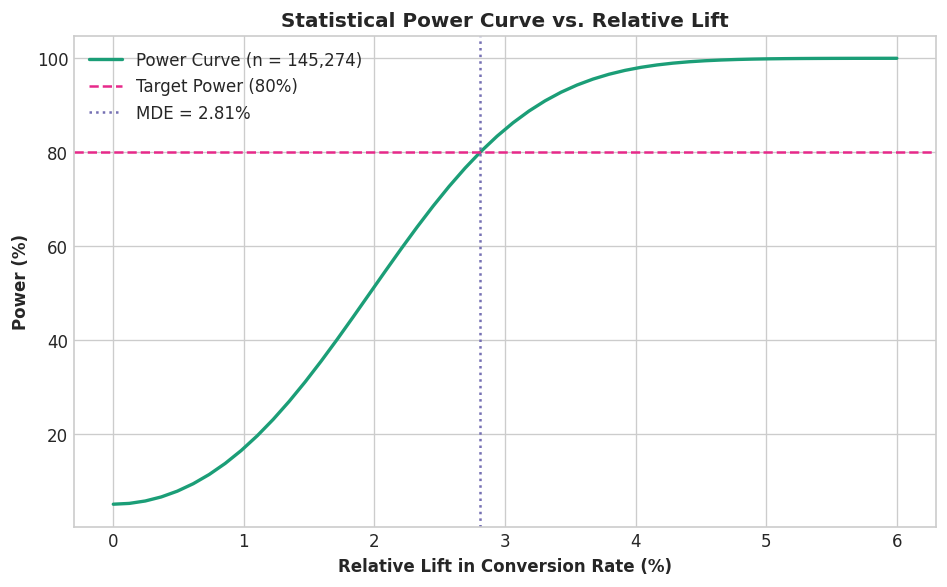

In [6]:
mde_res = calculate_mde(baseline_cr=metrics.cr_control, sample_size_per_group=metrics.n_control, alpha=0.05, power=0.80)
print(f"Prospective MDE (at 80% power): {mde_res.mde_relative_pct:.2f}% relative ({mde_res.mde_absolute_pp:.4f} percentage points)")

observed_power = calculate_statistical_power(
    baseline_cr=metrics.cr_control,
    effect_absolute=metrics.absolute_difference,
    sample_size_per_group=metrics.n_control,
    alpha=0.05
)
print(f"Post-hoc Power to detect observed effect (-0.16 pp): {observed_power*100:.2f}%")

# Generate power curve
power_curve = generate_power_curve(metrics.cr_control, metrics.n_control)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(power_curve["relative_lift_pct"], power_curve["power"] * 100, color="#1B9E77", lw=2, label="Power Curve (n = 145,274)")
ax.axhline(80, color="#E7298A", linestyle="--", label="Target Power (80%)")
ax.axvline(mde_res.mde_relative_pct, color="#7570B3", linestyle=":", label=f"MDE = {mde_res.mde_relative_pct:.2f}%")
ax.set_title("Statistical Power Curve vs. Relative Lift", fontweight="bold")
ax.set_xlabel("Relative Lift in Conversion Rate (%)", fontweight="bold")
ax.set_ylabel("Power (%)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Heterogeneity & Segment Interaction Modeling

We test whether the treatment effect varies across geographic territories using Logistic Regression with interaction terms:
$$\text{logit}(p) = \beta_0 + \beta_1 \text{Treatment} + \beta_2 \text{Country} + \beta_3 (\text{Treatment} \times \text{Country})$$


In [7]:
merged = clean_df.merge(countries_df, on="user_id", how="inner")
merged["treatment"] = (merged["group"] == "treatment").astype(int)

# Logistic regression with interaction
logit_model = smf.logit("converted ~ treatment * C(country)", data=merged).fit()
display(logit_model.summary())


Optimization terminated successfully.
         Current function value: 0.366109
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290578
Method:                           MLE   Df Model:                            5
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:               3.482e-05
Time:                        11:16:29   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1920
==============================================================================================
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept                     -2.0040      0.036    -55.008      0.000      -2.075      -1.933
C(country)[T.UK]               0.0118      0.040      0.296      0.767      -0.066       0.090
C(country)[T.US]               0.0175      0.038      0.465      0.642      -0.056       0.091
treatment                     -0.0674      0.052     -1.297      0.195      -0.169       0.034
treatment:C(country)[T.UK]     0.0783      0.057      1.378      0.168      -0.033       0.190
treatment:C(country)[T.US]     0.0469      0.054      0.872      0.383      -0.059       0.152
==============================================================================================
"""

## 7. Bayesian A/B Testing: Beta-Binomial Conjugate Analysis

Frequentist tests tell us $P(\text{Data} \mid H_0)$. Bayesian inference directly answers the product question:
**What is the probability that the new page is superior to the old page?**


Posterior Mean Control CR:    12.0392%
Posterior Mean Treatment CR:  11.8813%
P(Treatment > Control):       9.53%
P(Control > Treatment):       90.47%
Expected Loss (Deploy Treat): 0.1629 percentage points
95% Bayesian Credible Interval: [-0.3933%, +0.0798%] pp


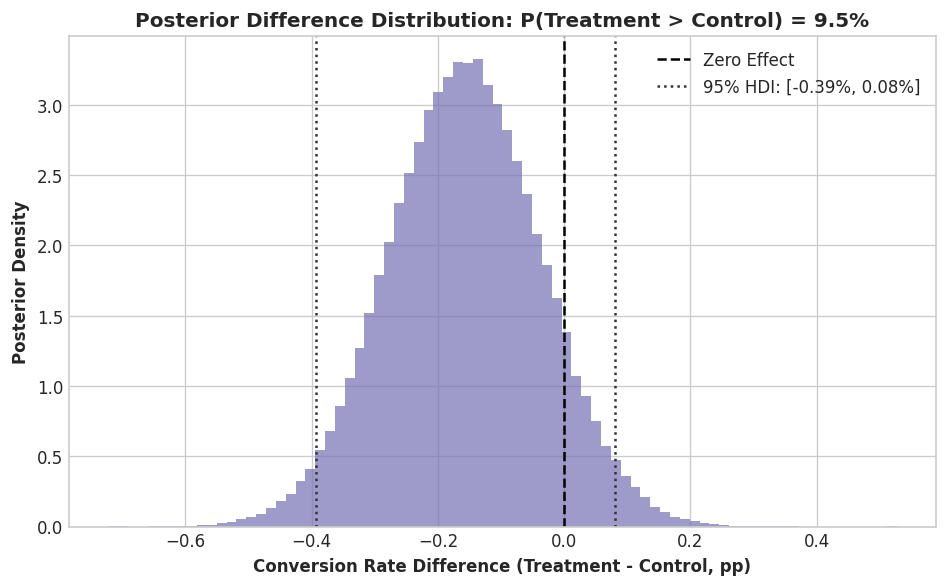

In [8]:
bayes_res, s_c, s_t, s_diff = run_bayesian_ab_test(
    metrics.conversions_control, metrics.n_control,
    metrics.conversions_treatment, metrics.n_treatment,
    n_samples=200000, seed=42
)

print(f"Posterior Mean Control CR:    {bayes_res.posterior_mean_ctrl*100:.4f}%")
print(f"Posterior Mean Treatment CR:  {bayes_res.posterior_mean_treat*100:.4f}%")
print(f"P(Treatment > Control):       {bayes_res.prob_treatment_beats_control*100:.2f}%")
print(f"P(Control > Treatment):       {(1.0 - bayes_res.prob_treatment_beats_control)*100:.2f}%")
print(f"Expected Loss (Deploy Treat): {bayes_res.expected_loss_treatment*100:.4f} percentage points")
print(f"95% Bayesian Credible Interval: [{bayes_res.credible_interval_95_lower_pp:+.4f}%, {bayes_res.credible_interval_95_upper_pp:+.4f}%] pp")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(s_diff * 100, bins=80, density=True, color="#7570B3", alpha=0.7)
ax.axvline(0, color="black", linestyle="--", label="Zero Effect")
ax.axvline(bayes_res.credible_interval_95_lower_pp, color="#333333", linestyle=":", label=f"95% HDI: [{bayes_res.credible_interval_95_lower_pp:.2f}%, {bayes_res.credible_interval_95_upper_pp:.2f}%]")
ax.axvline(bayes_res.credible_interval_95_upper_pp, color="#333333", linestyle=":")
ax.set_title(f"Posterior Difference Distribution: P(Treatment > Control) = {bayes_res.prob_treatment_beats_control*100:.1f}%", fontweight="bold")
ax.set_xlabel("Conversion Rate Difference (Treatment - Control, pp)", fontweight="bold")
ax.set_ylabel("Posterior Density", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()


## 8. Final Product Recommendation & Decision

### Recommendation: **No demonstrated conversion improvement**

1. **Statistical Evidence**:
   - Two-proportion Z-test p-value is **0.1899**, which exceeds the $\alpha = 0.05$ threshold. We fail to reject the null hypothesis $H_0$.
   - The 95% Confidence Interval for the difference in conversion rates is **[-0.39 pp, +0.08 pp]**.
   - The interval includes zero and is compatible with both modest harm and a small benefit; it does not prove the true effect is bounded at the displayed endpoint.
2. **Bayesian Risk Assessment**:
   - Under the stated Beta(1, 1) priors and this cohort, the posterior probability that treatment is better is approximately **9.53%**. This is model-conditional evidence, not certainty.
   - Launching treatment incurs an expected loss of **0.16 percentage points** of conversion.
3. **Engineering & Business Practicality**:
   - The experiment does not establish a conversion improvement. Consider design research and a better-instrumented follow-up experiment before deciding on rollout.
4. **Actionable Next Steps**:
   - Do not claim a conversion lift from this experiment; retaining the current page pending further evidence is a cautious option.
   - Investigate assignment/exposure inconsistencies and conduct qualitative research before a follow-up experiment.
